# 04 Prescriptive analysis: who gets the limited referral slots? (PB5)
Group 5 PROHI: Risk Factor Prediction of Chronic Kidney Disease

**User story:** As a Clinical Care Coordinator, I want to know which patients should get the limited referral slots so that the highest-risk patients are seen first.

**Owner:** Pasanka  |  **Depends on:** PB4 (final predicted risks)

Flow: draft risk scores → triage rules (shallow tree) → threshold analysis → OR-Tools slots (N = 5, 10, 15) → what-if with odds ratios → recommendation.

In [1]:
GITHUB_USER = "mhoyor"

import os, sys, subprocess
if not os.path.exists("data_prep.py"):          # Colab: clone the team repo
    if not os.path.exists("ckd-risk-app"):
        subprocess.run(["git", "clone", f"https://github.com/{GITHUB_USER}/ckd-risk-app.git"], check=True)
    os.chdir("ckd-risk-app")
sys.path.insert(0, os.getcwd())
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ortools"], check=False)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'ortools'], returncode=0)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import confusion_matrix, roc_auc_score
from ortools.sat.python import cp_model

from data_prep import load_data, FEATURES          # FEATURES = data version 1 predictors (no leakage columns)
from viz import apply_style, COLORS, MUTED, MODEL_COLORS, MODEL_STYLES, plot_readable_tree

apply_style()
os.makedirs("figures", exist_ok=True)
RANDOM_STATE = 42

## 1. Load data version 1
`load_data()` already removes the metadata rows, encodes the range labels as ordered numbers and keeps the leakage columns (`affected`, `stage`, `grf`) out of `FEATURES`. A few cells are missing, so we fill them with the most common value. `stage` is **not** a model input; it is only used later for a business rule.

In [3]:
d = load_data()
df, raw = d["all"], d["raw"]
y = df["class"]                                    # 1 = CKD
X = df[FEATURES].copy()
X = X.fillna(X.mode().iloc[0])
train_idx, test_idx = d["train"].index, d["test"].index   # team split: 80/20, random_state=42
print("Patients:", len(df), "| CKD:", int(y.sum()), "| not CKD:", int((1 - y).sum()), "| features:", X.shape[1])

def sens_spec(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tp / (tp + fn), tn / (tn + fp)

Patients: 200 | CKD: 128 | not CKD: 72 | features: 25


## 2. Draft risk scores (logistic regression)
Risk = predicted probability of CKD. To score **every** patient honestly we use 5-fold out-of-fold predictions (each patient is scored by a model that never saw them).

🔁 **When PB4 delivers its final risks:** replace the `risk` line below with PB4's values (same patient order). Everything after this cell re-runs unchanged.

⚠️ An AUC this close to 1 means these 200 patients are almost perfectly separable (strong lab values such as haemoglobin, albumin, creatinine). Treat exact probabilities with caution; the *ranking* is what matters. Mention this limitation in the report.

In [4]:
lr = LogisticRegression(max_iter=5000, C=1.0)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
risk = pd.Series(cross_val_predict(lr, X, y, cv=cv, method="predict_proba")[:, 1], index=X.index, name="risk")
# risk = <PB4 final risks here>
print("Out-of-fold AUC:", round(roc_auc_score(y, risk), 3))

Out-of-fold AUC: 0.999


## 3. Triage rules from a shallow decision tree
Depth 2 and depth 3 trees, trained on the team's 80% train split and evaluated on the 20% test split. The diagram turns coded splits into readable lab ranges.


=== Depth 2 | test sensitivity 84.6% | test specificity 100.0% | test n = 40 ===
|--- hemo <= 5.50
|   |--- pcv <= 6.50
|   |   |--- class: 1
|   |--- pcv >  6.50
|   |   |--- class: 0
|--- hemo >  5.50
|   |--- al <= 0.50
|   |   |--- class: 0
|   |--- al >  0.50
|   |   |--- class: 1



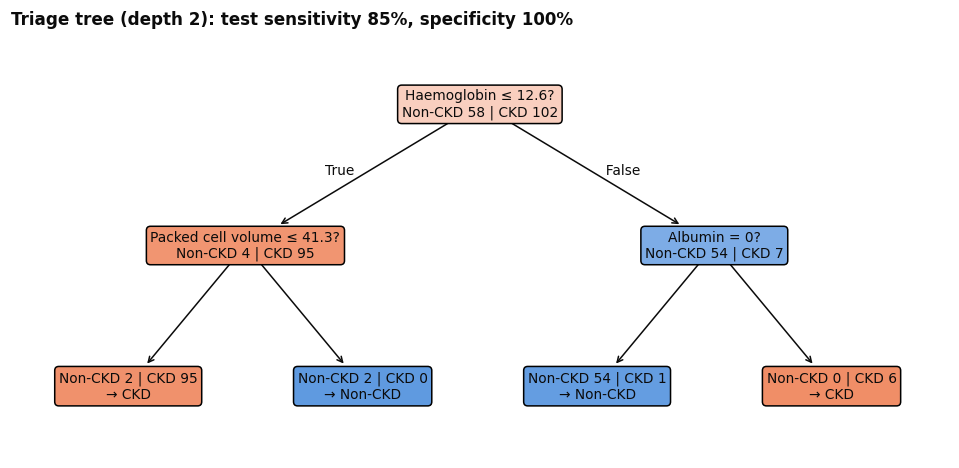


=== Depth 3 | test sensitivity 92.3% | test specificity 100.0% | test n = 40 ===
|--- hemo <= 5.50
|   |--- pcv <= 6.50
|   |   |--- sod <= 5.50
|   |   |   |--- class: 1
|   |   |--- sod >  5.50
|   |   |   |--- class: 0
|   |--- pcv >  6.50
|   |   |--- class: 0
|--- hemo >  5.50
|   |--- sg <= 2.50
|   |   |--- class: 1
|   |--- sg >  2.50
|   |   |--- su <= 0.50
|   |   |   |--- class: 0
|   |   |--- su >  0.50
|   |   |   |--- class: 1



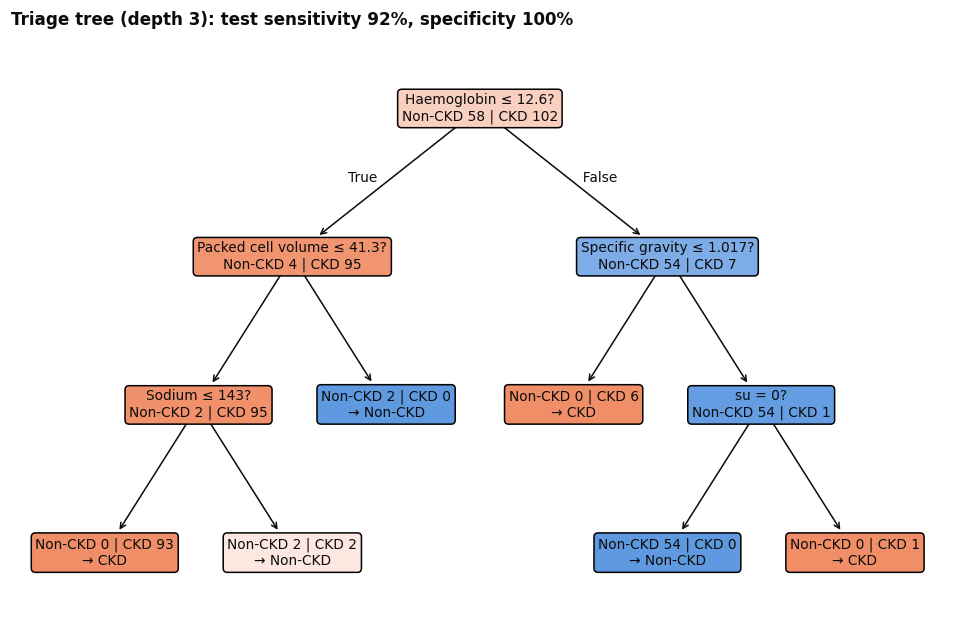

In [5]:
NAMES = {"hemo": "Haemoglobin", "al": "Albumin", "sod": "Sodium", "pcv": "Packed cell volume",
         "sc": "Serum creatinine", "bu": "Blood urea", "sg": "Specific gravity", "htn": "Hypertension",
         "dm": "Diabetes", "bgr": "Blood glucose", "rbcc": "Red cell count"}
tree_results = {}
for depth in (2, 3):
    t = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE).fit(X.loc[train_idx], y.loc[train_idx])
    se, sp = sens_spec(y.loc[test_idx], t.predict(X.loc[test_idx]))
    tree_results[depth] = (t, se, sp)
    print(f"\n=== Depth {depth} | test sensitivity {se:.1%} | test specificity {sp:.1%} | test n = {len(test_idx)} ===")
    print(export_text(t, feature_names=list(X.columns)))
    fig, ax = plt.subplots(figsize=(11, 5 if depth == 2 else 7))
    plot_readable_tree(ax, t, list(X.columns), raw=raw, names=NAMES)
    ax.set_title(f"Triage tree (depth {depth}): test sensitivity {se:.0%}, specificity {sp:.0%}")
    plt.savefig(f"figures/pb5_triage_tree_depth{depth}.png"); plt.show()

## 4. Threshold analysis (0.1 – 0.9)
A patient is flagged "high risk" when `risk ≥ threshold`. We need **sensitivity ≥ 95%** (miss almost no true CKD patients) and, subject to that, the highest threshold (fewest false alarms).

 threshold  sensitivity  specificity  flagged
      0.10        1.000        0.903      135
      0.15        1.000        0.944      132
      0.20        1.000        0.944      132
      0.25        1.000        0.944      132
      0.30        1.000        0.972      130
      0.35        0.992        0.972      129
      0.40        0.992        0.972      129
      0.45        0.992        0.972      129
      0.50        0.992        0.972      129
      0.55        0.984        0.986      127
      0.60        0.969        0.986      125
      0.65        0.969        0.986      125
      0.70        0.961        0.986      124
      0.75        0.945        0.986      122
      0.80        0.938        1.000      120
      0.85        0.922        1.000      118
      0.90        0.906        1.000      116

Chosen threshold: 0.7


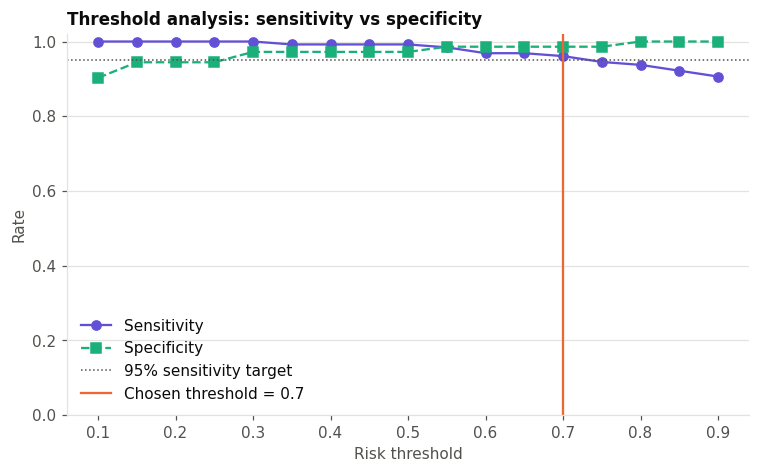

In [6]:
thr = np.round(np.arange(0.1, 0.9001, 0.05), 2)
rows = []
for t in thr:
    se, sp = sens_spec(y, (risk >= t).astype(int))
    rows.append((t, se, sp, int((risk >= t).sum())))
th = pd.DataFrame(rows, columns=["threshold", "sensitivity", "specificity", "flagged"])
ok = th[th.sensitivity >= 0.95]
CHOSEN = float(ok.threshold.max()) if len(ok) else float(th.threshold.min())
print(th.round(3).to_string(index=False))
print("\nChosen threshold:", CHOSEN)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(th.threshold, th.sensitivity, marker="o", color=MODEL_COLORS["Full model"], ls=MODEL_STYLES["Full model"], label="Sensitivity")
ax.plot(th.threshold, th.specificity, marker="s", color=MODEL_COLORS["Cheap-test model"], ls=MODEL_STYLES["Cheap-test model"], label="Specificity")
ax.axhline(0.95, color=MUTED, lw=1, ls=":", label="95% sensitivity target")
ax.axvline(CHOSEN, color=COLORS["CKD"], lw=1.5, label=f"Chosen threshold = {CHOSEN}")
ax.set_xlabel("Risk threshold"); ax.set_ylabel("Rate"); ax.set_ylim(0, 1.02)
ax.set_title("Threshold analysis: sensitivity vs specificity"); ax.legend(loc="lower left")
plt.savefig("figures/pb5_threshold_chart.png"); plt.show()

## 5. OR-Tools: who gets the N referral slots?
**Model:** one yes/no variable per patient. Maximise the total risk of referred patients, with at most N referrals, and only patients at or above the chosen threshold are eligible.

Because the model almost perfectly separates the groups, many CKD patients share a risk of ≈ 1.0, so "highest N risks" is mostly a tie. Ties are broken towards the more advanced stage.

We also run a **business-rule variant**: at least half of the slots must go to *early-stage* patients (stage 2–3), because referral can still slow their progression. Stage is only used as a rule the care team can change (set `EARLY_SHARE = 0` to switch it off).

In [7]:
stage_num = df["stage"].str.extract(r"(\d)")[0].astype(int)
early = stage_num.isin([2, 3]).astype(int)
EARLY_SHARE = 0.5

def solve(N, min_early=0, eligible_thr=CHOSEN):
    m = cp_model.CpModel()
    n = len(df)
    x = [m.NewBoolVar(f"x{i}") for i in range(n)]
    score = (risk * 10000).round().astype(int).tolist()
    for i in range(n):
        if risk.iloc[i] < eligible_thr:
            m.Add(x[i] == 0)
    m.Add(sum(x) <= N)
    if min_early:
        m.Add(sum(x[i] for i in range(n) if early.iloc[i]) >= min_early)
    m.Maximize(sum((score[i] * 10 + int(stage_num.iloc[i])) * x[i] for i in range(n)))   # tie-break: higher stage
    s = cp_model.CpSolver(); status = s.Solve(m)
    assert status in (cp_model.OPTIMAL, cp_model.FEASIBLE), "infeasible"
    return [df.index[i] for i in range(n) if s.Value(x[i])]

results = {}
for N in (5, 10, 15):
    for label, ms in (("pure risk", 0), ("≥50% early (s2-3)", int(np.ceil(N * EARLY_SHARE)))):
        idx = solve(N, ms)
        results[(N, label)] = idx
        print(f"N={N:>2} | {label:<18} | total risk {risk.loc[idx].sum():.2f} | early-stage: {int(early.loc[idx].sum())}")

sel = pd.DataFrame({"risk": risk.round(4), "stage": df["stage"], "true_CKD": y})
for N in (5, 10, 15):
    for label in ("pure risk", "≥50% early (s2-3)"):
        print(f"\n--- N = {N} ({label}) ---")
        print(sel.loc[results[(N, label)]].sort_values("risk", ascending=False).to_string())

N= 5 | pure risk          | total risk 5.00 | early-stage: 0
N= 5 | ≥50% early (s2-3)  | total risk 5.00 | early-stage: 3
N=10 | pure risk          | total risk 10.00 | early-stage: 0
N=10 | ≥50% early (s2-3)  | total risk 10.00 | early-stage: 5
N=15 | pure risk          | total risk 15.00 | early-stage: 0
N=15 | ≥50% early (s2-3)  | total risk 15.00 | early-stage: 8

--- N = 5 (pure risk) ---
     risk stage  true_CKD
175   1.0    s5         1
178   1.0    s5         1
184   1.0    s5         1
192   1.0    s5         1
194   1.0    s5         1

--- N = 5 (≥50% early (s2-3)) ---
     risk stage  true_CKD
120   1.0    s3         1
123   1.0    s3         1
145   1.0    s3         1
178   1.0    s5         1
184   1.0    s5         1

--- N = 10 (pure risk) ---
     risk stage  true_CKD
113   1.0    s5         1
140   1.0    s5         1
141   1.0    s5         1
146   1.0    s5         1
163   1.0    s5         1
175   1.0    s5         1
178   1.0    s5         1
184   1.0    s5     

## 6. What-if example with odds ratios
For logistic regression, `exp(coefficient)` is the **odds ratio**: how many times the odds of CKD are multiplied when a feature goes up by one unit (for hypertension `htn` or diabetes `dm`: 0 → 1). We fit on all patients for interpretation.

In [8]:
lr_full = LogisticRegression(max_iter=5000, C=1.0).fit(X, y)
orr = pd.Series(np.exp(lr_full.coef_[0]), index=X.columns, name="odds_ratio")
print(orr.loc[["htn", "dm"]].round(2))
print("\nTop odds ratios:\n", orr.sort_values(ascending=False).head(8).round(2).to_string())

# patient WITHOUT htn whose risk is closest to the chosen threshold (most 'movable')
cand = X.index[X["htn"] == 0]
pid = (risk.loc[cand] - CHOSEN).abs().idxmin()
p0 = lr_full.predict_proba(X.loc[[pid]])[0, 1]
Xw = X.loc[[pid]].copy(); Xw["htn"] = 1
p1 = lr_full.predict_proba(Xw)[0, 1]
odds = lambda p: p / (1 - p)
print(f"\nPatient row {pid}: hypertension 0 -> 1")
print(f"Risk {p0:.1%} -> {p1:.1%}")
print(f"Odds {odds(p0):.3f} -> {odds(p1):.3f}  (ratio {odds(p1)/odds(p0):.2f}  vs  exp(coef) {orr['htn']:.2f})")

htn    2.03
dm     1.54
Name: odds_ratio, dtype: float64

Top odds ratios:
 al          3.02
htn         2.03
bgr         1.81
bp limit    1.79
bu          1.62
dm          1.54
appet       1.54
su          1.46

Patient row 47: hypertension 0 -> 1
Risk 85.2% -> 92.1%
Odds 5.756 -> 11.668  (ratio 2.03  vs  exp(coef) 2.03)


## 7. Recommendation for the care coordinator
(Generated from the results above, so it updates automatically when PB4's risks are plugged in.)

In [9]:
d3 = tree_results[3]
p10 = results[(10, "pure risk")]
print(f"""RECOMMENDATION
--------------
1. Rank every patient by predicted kidney-disease risk and refer the highest-risk patients first.
2. Treat a patient as high-risk when their risk score is {CHOSEN:.2f} or above. At this cut-off the check finds
   {th.loc[th.threshold==CHOSEN,'sensitivity'].iloc[0]:.0%} of patients who really have kidney disease, and wrongly flags
   {1-th.loc[th.threshold==CHOSEN,'specificity'].iloc[0]:.0%} of healthy patients.
3. With 5, 10 or 15 slots, use the ranked lists above (section 5). With 10 slots the referred group has an average
   risk of {risk.loc[p10].mean():.1%}. If you also want half of the slots protected for early-stage patients
   (where referral can still slow progression), use the second list; it gives up only
   {risk.loc[p10].sum()-risk.loc[results[(10,'≥50% early (s2-3)')]].sum():.2f} of total risk score.
4. Quick bedside rules: the depth-3 triage tree catches {d3[1]:.0%} of true cases on unseen patients
   (and {d3[2]:.0%} specificity). It is easy to apply by hand but misses more cases than the score, so prefer the score when available.
5. High blood pressure (htn) and diabetes (dm) raise the odds of kidney disease
   (about x{orr['htn']:.1f} and x{orr['dm']:.1f}), so patients with these conditions deserve a closer look.
6. Caution: only {len(df)} patients were used. This tool supports, and never replaces, the clinician's judgement.""")

RECOMMENDATION
--------------
1. Rank every patient by predicted kidney-disease risk and refer the highest-risk patients first.
2. Treat a patient as high-risk when their risk score is 0.70 or above. At this cut-off the check finds
   96% of patients who really have kidney disease, and wrongly flags
   1% of healthy patients.
3. With 5, 10 or 15 slots, use the ranked lists above (section 5). With 10 slots the referred group has an average
   risk of 100.0%. If you also want half of the slots protected for early-stage patients
   (where referral can still slow progression), use the second list; it gives up only
   0.00 of total risk score.
4. Quick bedside rules: the depth-3 triage tree catches 92% of true cases on unseen patients
   (and 100% specificity). It is easy to apply by hand but misses more cases than the score, so prefer the score when available.
5. High blood pressure (htn) and diabetes (dm) raise the odds of kidney disease
   (about x2.0 and x1.5), so patients with these co